# 📞 Aster Vale Pain Clinic — Exploratory Data Analysis
**FDE assignment · policy `assignment-v2` · 50 labeled call transcripts**

**Why this notebook exists.** Before writing a single prompt, I profiled the labeled data to find out *what the problem actually looks like*.
Every design decision in the pipeline (LLM for evidence, Python for policy, a deterministic date resolver, synthetic tests for unseen labels) traces back to a finding here.

| # | Section | Question it answers |
|---|---------|---------------------|
| 1 | Data integrity | Can I trust and correctly load the data? |
| 2 | Label distribution | How skewed is it, and what is the baseline to beat? |
| 3 | Coverage gaps | Which valid labels have **zero** examples? |
| 4 | `next_call_at` structure | Which rules produce the 20-point field? |
| 5 | Transcript characteristics | Length, speaker quirks, token budget |
| 6 | Scheduling language | How much date/time parsing is needed? |
| 7 | Cost & rate-limit budget | Is one LLM call per record or two affordable? |
| 8 | Design implications | What did I change because of this? |

> ⚠️ Gold labels are used **only** here, for analysis. They never enter the prediction path.

In [1]:
import sys, os, re, json
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# make `constants.py` importable whether the notebook runs from repo root or a subfolder
for p in [Path.cwd(), Path.cwd().parent]:
    if (p / "constants.py").exists():
        sys.path.insert(0, str(p)); ROOT = p; break
from constants import VALID_PAIRS

DATA = next(iter(sorted((ROOT / "data").glob("*.xlsx"))))     # the workbook placed in data/
FIG_DIR = ROOT / "analysis" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- consistent, readable style ----
PALETTE = {"Appointment Scheduled": "#2E7D32", "Follow-up Required": "#1565C0", "Not Interested": "#C62828",
           "Invalid Lead": "#6A1B9A", "Unable to Assess": "#EF6C00"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.axisbelow": True,
                     "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold"})
pd.set_option("display.max_colwidth", 80, "display.width", 140)

def save(fig, name): fig.savefig(FIG_DIR / f"{name}.png", dpi=140, bbox_inches="tight")
print("workbook:", DATA.name)

workbook: workbook.xlsx


## 1 · Data integrity
The workbook has quirks that silently corrupt a naive load. I check each one explicitly.

In [2]:
# keep_default_na=False: the sheet uses the LITERAL TEXT "null"; pandas would silently turn it into NaN.
df = pd.read_excel(DATA, sheet_name="50 Labeled Calls", keep_default_na=False, dtype=str)
df["call_dt"] = pd.to_datetime(df.call_started_at.map(lambda s: datetime.fromisoformat(s).replace(tzinfo=None)))
df["next_is_null"] = df.next_call_at.str.strip().str.lower().eq("null")

iso = re.compile(r"^\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}\+05:30$")
bad_pairs = [r.transcript_id for r in df.itertuples() if r.sub_disposition not in VALID_PAIRS.get(r.disposition, [])]
bad_ts = df[~df.next_is_null & ~df.next_call_at.str.match(iso)].transcript_id.tolist()
t0 = df.transcript.iloc[0]

checks = pd.DataFrame([
    ("Row count", len(df), len(df) == 50),
    ("Unique transcript_id", df.transcript_id.is_unique, df.transcript_id.is_unique),
    ("Timezones present", ", ".join(df.timezone.unique()), df.timezone.nunique() == 1),
    ("Call date range", f"{df.call_dt.min():%d %b} → {df.call_dt.max():%d %b %Y}", True),
    ('Literal "null" in next_call_at', int(df.next_is_null.sum()), True),
    ("Real newlines in transcript (vs literal \\n)", f"{t0.count(chr(10))} real / {t0.count(chr(92)+'n')} literal", t0.count(chr(10)) > 0),
    ("Gold pairs that violate the policy", len(bad_pairs), not bad_pairs),
    ("Timestamps not ISO-8601 +05:30", len(bad_ts), not bad_ts),
    ("Empty transcripts", int((df.transcript.str.strip() == "").sum()), (df.transcript.str.strip() != "").all()),
], columns=["Check", "Result", "OK"])
checks["OK"] = checks.OK.map({True: "✅", False: "⚠️"})
checks.style.hide(axis="index").set_properties(**{"text-align": "left"})

Check,Result,OK
Row count,50,✅
Unique transcript_id,True,✅
Timezones present,Asia/Kolkata,✅
Call date range,12 Oct → 18 Oct 2026,✅
"Literal ""null"" in next_call_at",14,✅
Real newlines in transcript (vs literal \n),76 real / 0 literal,✅
Gold pairs that violate the policy,0,✅
Timestamps not ISO-8601 +05:30,0,✅
Empty transcripts,0,✅


**Findings.** 14 `next_call_at` values are the *text* `null`, which must become JSON `null` — and pandas would have turned them into `NaN`
(the output contract requires an actual JSON null). Transcripts contain real newlines, so splitting by line to get speaker turns is safe.
All gold labels are internally valid, so they can be trusted as an evaluation reference.

## 2 · Label distribution
How skewed is the data? Any model has to beat the majority-class baseline to prove it learned anything.

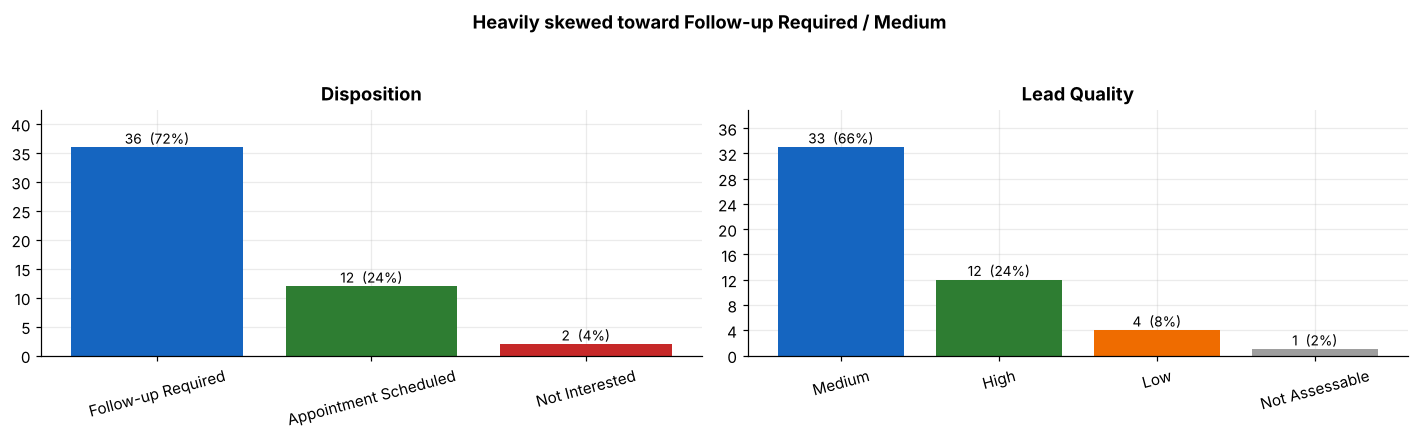

Field,Majority-class baseline
disposition,72%
sub_disposition,28%
lead_quality,66%
next_call_at is null,28%


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, col, colors in [(ax[0], "disposition", [PALETTE[d] for d in df.disposition.value_counts().index]),
                       (ax[1], "lead_quality", ["#1565C0", "#2E7D32", "#EF6C00", "#9E9E9E"])]:
    vc = df[col].value_counts()
    bars = a.bar(vc.index, vc.values, color=colors[:len(vc)])
    for b, v in zip(bars, vc.values):
        a.text(b.get_x() + b.get_width()/2, v + .6, f"{v}  ({v/len(df):.0%})", ha="center", fontsize=9)
    a.set_title(col.replace("_", " ").title()); a.set_ylim(0, vc.max() * 1.18)
    a.tick_params(axis="x", rotation=15); a.yaxis.set_major_locator(MaxNLocator(integer=True))
fig.suptitle("Heavily skewed toward Follow-up Required / Medium", fontweight="bold", y=1.04)
plt.tight_layout(); save(fig, "01_disposition_leadquality"); plt.show()

base = pd.DataFrame({"Field": ["disposition", "sub_disposition", "lead_quality", "next_call_at is null"],
    "Majority-class baseline": [f"{df.disposition.value_counts(normalize=True).iloc[0]:.0%}",
                                f"{df.sub_disposition.value_counts(normalize=True).iloc[0]:.0%}",
                                f"{df.lead_quality.value_counts(normalize=True).iloc[0]:.0%}",
                                f"{df.next_is_null.mean():.0%}"]})
base.style.hide(axis="index")

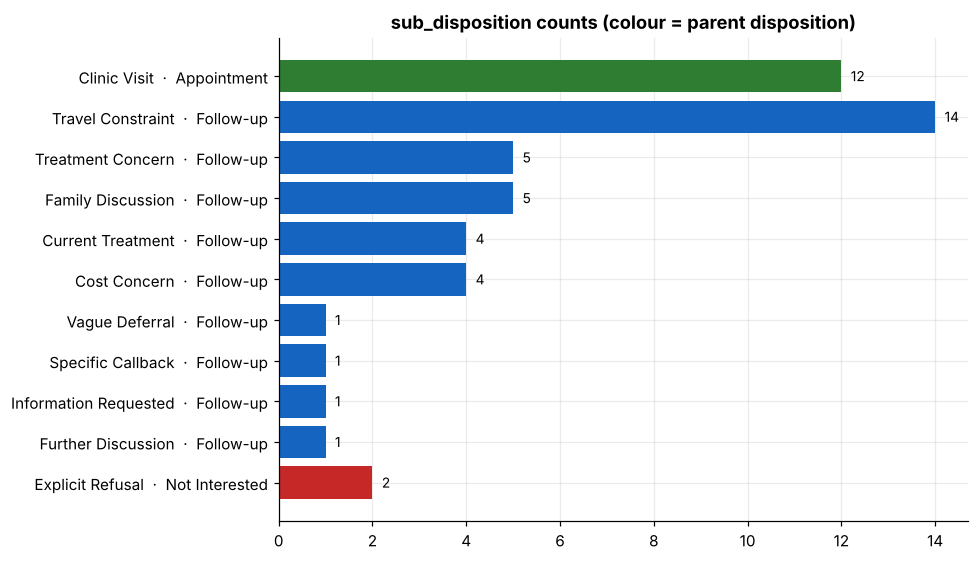

In [4]:
sub = (df.groupby(["disposition", "sub_disposition"]).size().rename("n").reset_index()
         .sort_values(["disposition", "n"], ascending=[False, True]))
fig, ax = plt.subplots(figsize=(9, 5.2))
labels = sub.sub_disposition + "  ·  " + sub.disposition.str.replace(" Required", "").str.replace(" Scheduled", "")
bars = ax.barh(labels, sub.n, color=sub.disposition.map(PALETTE))
for b, v in zip(bars, sub.n): ax.text(v + .2, b.get_y() + b.get_height()/2, int(v), va="center", fontsize=9)
ax.set_title("sub_disposition counts (colour = parent disposition)"); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout(); save(fig, "02_sub_disposition"); plt.show()

In [5]:
# How lead quality relates to sub_disposition — shows the rules that matter for the Python policy engine
ct = pd.crosstab([df.disposition, df.sub_disposition], df.lead_quality)
ct.style.background_gradient(cmap="Blues", axis=None).format("{:d}")

**Findings**
- **72 %** of calls are *Follow-up Required*; always predicting it already scores 72 % on disposition. Real skill shows only in the minority classes and in sub_disposition.
- **Travel Constraint is the single biggest class (14/50 = 28 %)** — the gold labels apply it broadly (out of town, working hours, companion away, "next week"), so few-shot examples must teach that boundary.
- **Lead quality is almost determined by disposition**: every Appointment is *High*, almost every Follow-up is *Medium*. The exceptions (*Low*, *Not Assessable*) are the interesting cases and need rule-based logic, not a model guess.

## 3 · Coverage gaps — valid labels with zero examples
The private evaluation set will likely contain labels that never appear in these 50 calls. Counting them tells me where I cannot validate on real data.

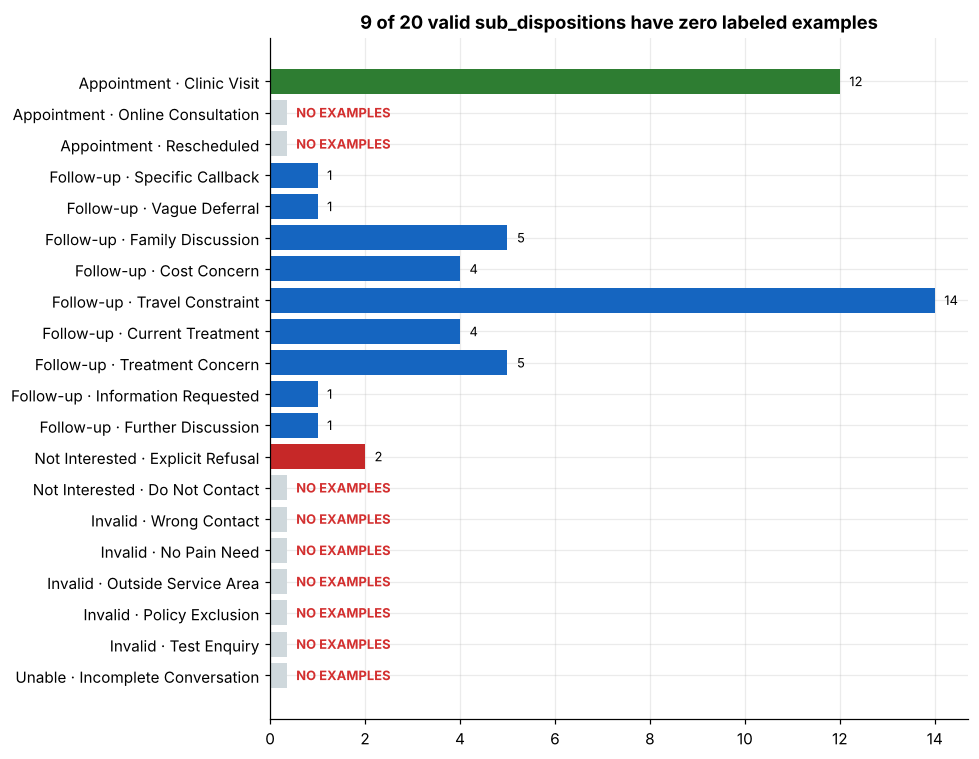

Singleton classes (n=1 → cannot be split into dev/holdout): Further Discussion, Information Requested, Vague Deferral, Specific Callback


In [6]:
rows = [(d, s, int(((df.disposition == d) & (df.sub_disposition == s)).sum())) for d, subs in VALID_PAIRS.items() for s in subs]
cov = pd.DataFrame(rows, columns=["disposition", "sub_disposition", "n"])
cov = cov.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 7))
SHORT = {"Appointment Scheduled": "Appointment", "Follow-up Required": "Follow-up", "Not Interested": "Not Interested",
         "Invalid Lead": "Invalid", "Unable to Assess": "Unable"}
colors = [("#CFD8DC" if n == 0 else PALETTE[d]) for d, n in zip(cov.disposition, cov.n)]
ax.barh(cov.disposition.map(SHORT) + " · " + cov.sub_disposition, cov.n.clip(lower=.35), color=colors)
for i, n in enumerate(cov.n): ax.text(max(n, .35) + .2, i, "NO EXAMPLES" if n == 0 else n, va="center", fontsize=8.5,
                                       color="#D32F2F" if n == 0 else "black", fontweight="bold" if n == 0 else None)
ax.set_title(f"{(cov.n == 0).sum()} of {len(cov)} valid sub_dispositions have zero labeled examples"); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout(); save(fig, "03_coverage_gaps"); plt.show()

singles = cov[cov.n == 1]
print("Singleton classes (n=1 → cannot be split into dev/holdout):", ", ".join(singles.sub_disposition))

**Implication.** No Invalid Lead, no Unable to Assess, no Online Consultation, no Rescheduled, no Do Not Contact in the labeled set. I cannot measure accuracy on them,
so I will (a) keep their rules in **deterministic Python**, and (b) write **synthetic mini-transcripts as unit tests** for each. Classes with a single example cannot be stratified,
so holdout metrics will be reported with a small-sample caveat.

## 4 · `next_call_at` — the 20-point field
Which rules produce the gold timestamps? This decides how much logic belongs in code rather than in the LLM.

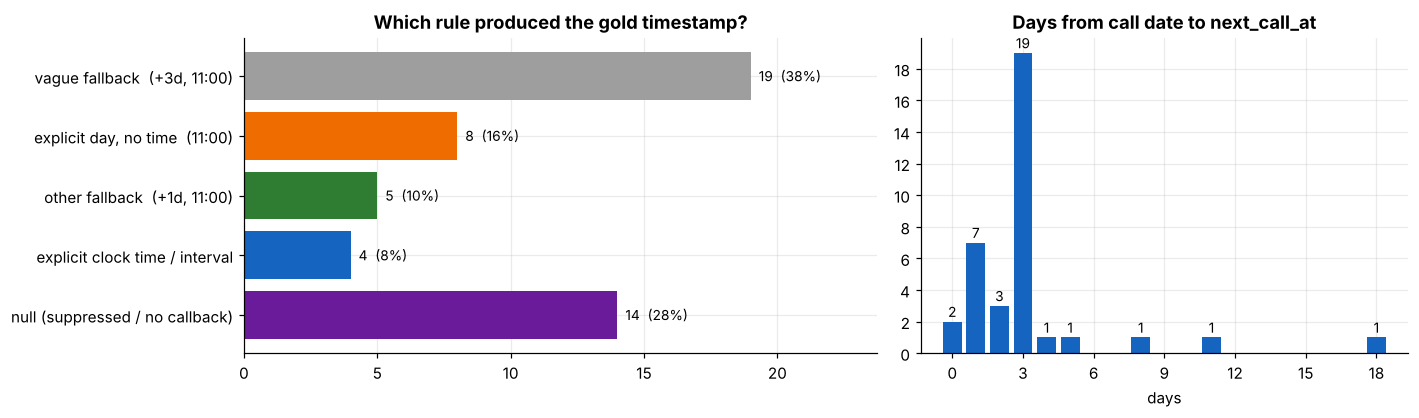

In [7]:
rows = []
for r in df.itertuples():
    if r.next_is_null:
        rows.append((r.transcript_id, r.disposition, r.sub_disposition, np.nan, None, "null (suppressed / no callback)")); continue
    t1 = datetime.fromisoformat(r.next_call_at).replace(tzinfo=None)
    gap = (t1.date() - r.call_dt.date()).days; clock = t1.strftime("%H:%M:%S")
    if clock == "11:00:00" and gap == 3: b = "vague fallback  (+3d, 11:00)"
    elif clock == "11:00:00" and gap == 1: b = "other fallback  (+1d, 11:00)"
    elif clock == "11:00:00": b = "explicit day, no time  (11:00)"
    else: b = "explicit clock time / interval"
    rows.append((r.transcript_id, r.disposition, r.sub_disposition, gap, clock, b))
nx = pd.DataFrame(rows, columns=["id", "disposition", "sub_disposition", "day_gap", "clock", "bucket"])

order = ["vague fallback  (+3d, 11:00)", "explicit day, no time  (11:00)", "other fallback  (+1d, 11:00)",
         "explicit clock time / interval", "null (suppressed / no callback)"]
vc = nx.bucket.value_counts().reindex(order)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.9), gridspec_kw={"width_ratios": [1.3, 1]})
bars = ax[0].barh(vc.index[::-1], vc.values[::-1], color=["#9E9E9E", "#EF6C00", "#2E7D32", "#1565C0", "#6A1B9A"][::-1])
for b, v in zip(bars, vc.values[::-1]): ax[0].text(v + .3, b.get_y() + b.get_height()/2, f"{v}  ({v/len(nx):.0%})", va="center", fontsize=9)
ax[0].set_title("Which rule produced the gold timestamp?"); ax[0].set_xlim(0, vc.max() * 1.25)
g = nx.day_gap.dropna().astype(int).value_counts().sort_index()
ax[1].bar(g.index, g.values, color="#1565C0")
for x, v in g.items(): ax[1].text(x, v + .3, v, ha="center", fontsize=9)
ax[1].set_title("Days from call date to next_call_at"); ax[1].set_xlabel("days"); ax[1].xaxis.set_major_locator(MaxNLocator(integer=True)); ax[1].yaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout(); save(fig, "04_next_call_at"); plt.show()

In [8]:
summary = pd.DataFrame({
    "Non-null next_call_at": [int((~nx.day_gap.isna()).sum())],
    "…at exactly 11:00": [int((nx.clock == "11:00:00").sum())],
    "Appointments with a distinct callback": [int(((nx.disposition == "Appointment Scheduled") & nx.day_gap.notna()).sum())],
    "Suppression violations (NI/Invalid/Unable non-null)": [int(((~nx.disposition.isin(["Follow-up Required", "Appointment Scheduled"])) & nx.day_gap.notna()).sum())],
}).T.rename(columns={0: "count"})
display(summary)
display(nx[nx.bucket == "explicit clock time / interval"][["id", "sub_disposition", "day_gap", "clock"]].reset_index(drop=True))

,count
Non-null next_call_at,36
…at exactly 11:00,32
Appointments with a distinct callback,0
Suppression violations (NI/Invalid/Unable non-null),0


,id,sub_disposition,day_gap,clock
0,AVT-004,Family Discussion,1.0,18:00:00
1,AVT-011,Family Discussion,1.0,15:00:00
2,AVT-044,Travel Constraint,0.0,18:00:00
3,AVT-047,Treatment Concern,0.0,14:26:01


**Findings**
- **32 of 36 non-null values are at exactly 11:00** and most sit at +3 or +1 days: the gold set is dominated by the *fallback rules* (vague → +3 d, nothing agreed → +1 d), not by explicit callback times.
- Only **4** values carry an explicit clock time (e.g. *tomorrow evening → 18:00*, *in 15 minutes → 14:26:01 with seconds preserved*).
- Suppression holds perfectly in the data (no Not-Interested/Invalid/Unable call has a timestamp) and **no appointment carries a callback**.

⚠️ *Caveat:* a +1 / +3-day gap at 11:00 is **consistent with** a fallback but could also be an explicit "tomorrow"/"in three days". The bucketing is a heuristic for sizing the problem, not ground truth.

**Implication:** an LLM that "just writes a timestamp" will fail on these rules. The LLM should only report *what was said and whether it was acknowledged*; **Python applies the arithmetic and fallbacks**.

## 5 · Transcript characteristics
Length drives token cost and rate-limit risk; speaker-label quality drives how much role inference the prompt must do.

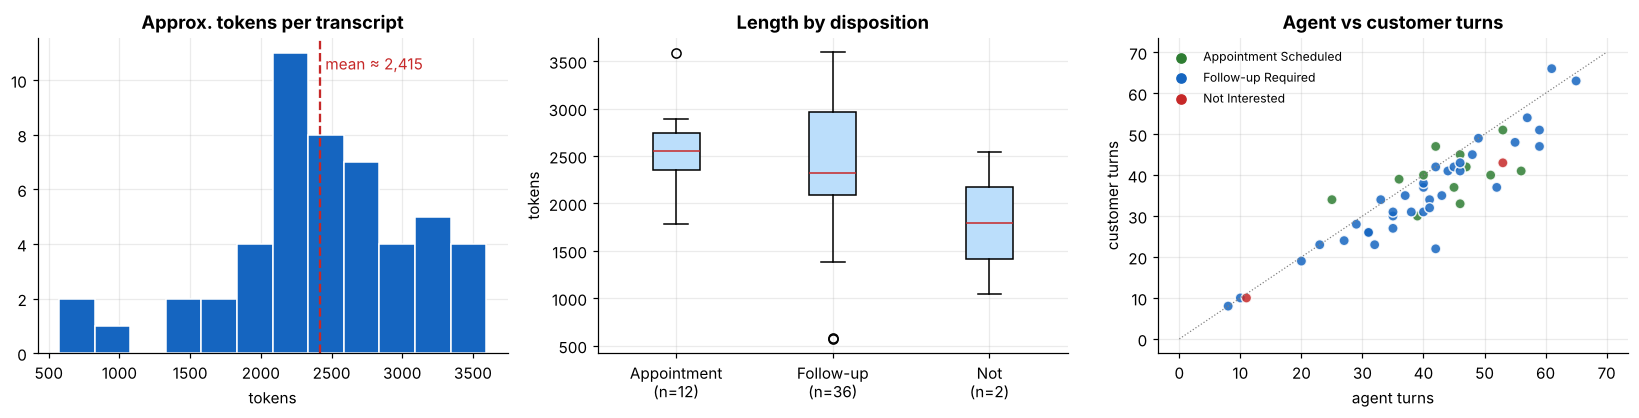

First speaker is 'Customer' in 17 of 50 calls → speaker labels are unreliable, roles must be inferred from dialogue.


,transcript_id,chars,n_turns,disposition,sub_disposition,lead_quality
0,AVT-042,1832,16,Follow-up Required,Treatment Concern,Not Assessable
1,AVT-022,1851,20,Follow-up Required,Treatment Concern,Low
2,AVT-033,3332,21,Not Interested,Explicit Refusal,Low


,count,mean,std,min,25%,50%,75%,max
chars,50.0,7732.0,2178.0,1832.0,6728.0,7688.0,9115.0,11501.0
tokens,50.0,2416.0,680.0,572.0,2102.0,2402.0,2848.0,3594.0
n_turns,50.0,77.0,24.0,16.0,64.0,78.0,90.0,128.0
agent_turns,50.0,41.0,13.0,8.0,35.0,42.0,48.0,65.0
cust_turns,50.0,36.0,12.0,8.0,30.0,37.0,43.0,66.0


In [9]:
def turns(t): return [l for l in t.split("\n") if l.strip()]
df["chars"] = df.transcript.str.len()
df["tokens"] = (df.chars / 3.2).astype(int)               # rough heuristic, ~3.2 chars/token for romanised Hindi-English
df["n_turns"] = df.transcript.map(lambda t: len(turns(t)))
df["agent_turns"] = df.transcript.map(lambda t: sum(l.startswith("Agent:") for l in turns(t)))
df["cust_turns"] = df.transcript.map(lambda t: sum(l.startswith("Customer:") for l in turns(t)))
df["first_speaker"] = df.transcript.map(lambda t: turns(t)[0].split(":")[0])

fig, ax = plt.subplots(1, 3, figsize=(15, 3.9))
ax[0].hist(df.tokens, bins=12, color="#1565C0", edgecolor="white")
ax[0].axvline(df.tokens.mean(), color="#C62828", ls="--"); ax[0].text(df.tokens.mean() + 40, ax[0].get_ylim()[1] * .9, f"mean ≈ {int(df.tokens.mean()):,}", color="#C62828")
ax[0].set_title("Approx. tokens per transcript"); ax[0].set_xlabel("tokens")
order_d = [d for d in PALETTE if d in df.disposition.unique()]
ax[1].boxplot([df[df.disposition == d].tokens for d in order_d], tick_labels=[f"{d.split()[0]}\n(n={int((df.disposition == d).sum())})" for d in order_d], patch_artist=True,
              boxprops=dict(facecolor="#BBDEFB"), medianprops=dict(color="#C62828"))
ax[1].set_title("Length by disposition"); ax[1].set_ylabel("tokens")
ax[2].scatter(df.agent_turns, df.cust_turns, c=df.disposition.map(PALETTE), s=45, alpha=.85, edgecolor="white")
ax[2].plot([0, 70], [0, 70], color="grey", lw=.8, ls=":")
for d in order_d: ax[2].scatter([], [], c=PALETTE[d], label=d)
ax[2].legend(fontsize=8, frameon=False); ax[2].set_title("Agent vs customer turns"); ax[2].set_xlabel("agent turns"); ax[2].set_ylabel("customer turns")
plt.tight_layout(); save(fig, "05_transcripts"); plt.show()

short = df.nsmallest(3, "chars")[["transcript_id", "chars", "n_turns", "disposition", "sub_disposition", "lead_quality"]]
print(f"First speaker is 'Customer' in {(df.first_speaker == 'Customer').sum()} of {len(df)} calls "
      f"→ speaker labels are unreliable, roles must be inferred from dialogue.")
display(short.reset_index(drop=True))
display(df[["chars", "tokens", "n_turns", "agent_turns", "cust_turns"]].describe().round(0).T)

**Findings**
- Mean ≈ 2.4k tokens (max ≈ 3.6k): small enough for a single-call context, but **LLM calls per record × 50 records** adds up on a rate-limited key (budgeted below).
- The first line is spoken by the *Customer* in about a third of calls — the label order cannot be trusted, so the prompt must say *"infer who is the agent from the dialogue."*
- Even the three shortest calls are labeled *Follow-up* or *Not Interested*, **none is Unable to Assess** — short ≠ incomplete. The shortest of all (AVT-042) is the only *Not Assessable* lead quality in the data, so it is the first case I will read closely when tuning that rule.
- The Not Interested boxplot rests on n = 2; read it as anecdote, not distribution.

## 6 · Scheduling language
How much date/time understanding does the pipeline need? Regex counts across all transcripts (rough sizing, not ground truth).

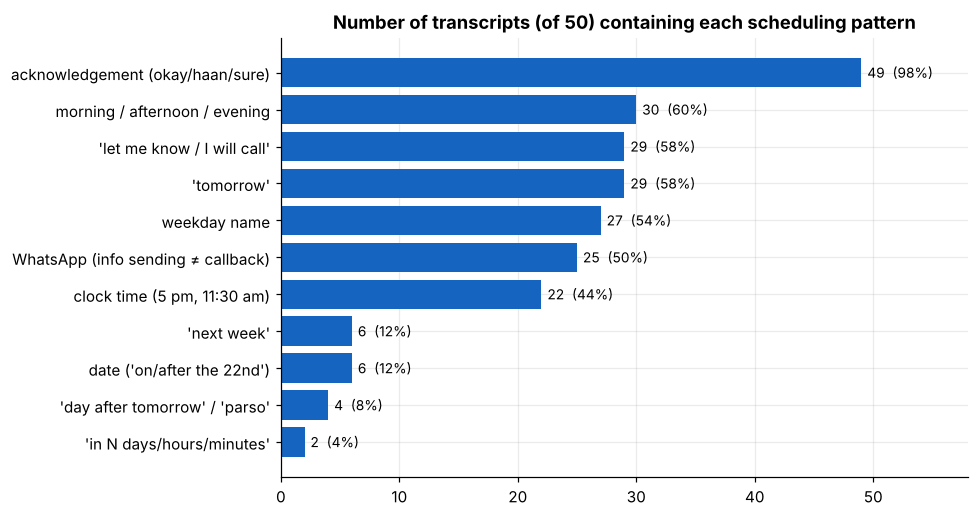

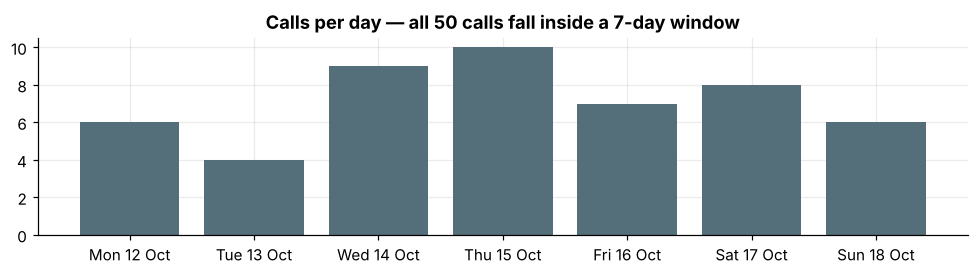

In [10]:
pats = {
    "'tomorrow'": r"\btomorrow\b", "'day after tomorrow' / 'parso'": r"day after tomorrow|\bparso\b",
    "weekday name": r"\b(?:monday|tuesday|wednesday|thursday|friday|saturday|sunday)\b",
    "'next week'": r"\bnext week\b", "date ('on/after the 22nd')": r"\b(?:after|on) the \d{1,2}(?:st|nd|rd|th)\b",
    "clock time (5 pm, 11:30 am)": r"\b\d{1,2}(?::\d{2})?\s?(?:am|pm)\b", "morning / afternoon / evening": r"\b(?:morning|afternoon|evening)\b",
    "'in N days/hours/minutes'": r"\bin \d+ (?:days?|hours?|minutes?)\b",
    "acknowledgement (okay/haan/sure)": r"\b(?:okay|haan|theek hai|sure)\b",
    "WhatsApp (info sending ≠ callback)": r"whatsapp", "'let me know / I will call'": r"let you know|i will call|i'll call|will tell you",
}
prev = pd.Series({k: int(df.transcript.str.contains(v, case=False, regex=True).sum()) for k, v in pats.items()}).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.barh(prev.index, prev.values, color="#1565C0")
for b, v in zip(bars, prev.values): ax.text(v + .5, b.get_y() + b.get_height()/2, f"{v}  ({v/len(df):.0%})", va="center", fontsize=9)
ax.set_xlim(0, 58); ax.set_title("Number of transcripts (of 50) containing each scheduling pattern")
plt.tight_layout(); save(fig, "06_scheduling_language"); plt.show()

cal = df.groupby(df.call_dt.dt.date).size()
fig, ax = plt.subplots(figsize=(9, 2.6)); ax.bar([d.strftime("%a %d %b") for d in cal.index], cal.values, color="#546E7A")
ax.set_title(f"Calls per day — all {len(df)} calls fall inside a {len(cal)}-day window"); ax.yaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout(); plt.show()

**Findings.** Relative days (*tomorrow*, *parso*), weekday names, clock times and part-of-day words each appear in **dozens** of calls, so the resolver must handle all of them — and
**"WhatsApp" appears in half the calls**, mostly as *information sending*, which the policy says is **not** a callback. Acknowledgement words appear in almost every call, so the prompt must
tie an acknowledgement to a *specific proposal*, not just detect the word.

All calls sit in a single **7-day window**, so weekday/date arithmetic is exercised on very few anchor dates. The resolver therefore needs **synthetic unit tests** on other anchors
(month ends, Sunday → Monday, late-night calls) rather than relying on these 50 records.

## 7 · Cost & rate-limit budget
A back-of-the-envelope estimate so the architecture choice (one vs. two LLM calls) is a *measured* decision. The two assumptions below are editable.

In [11]:
PROMPT_OVERHEAD_TOKENS = 1500     # system prompt + few-shot (assumption — will be measured once the prompt exists)
CALLS_PER_RECORD = 2              # journey-state call + scheduling-events call
OUTPUT_TOKENS_PER_CALL = 500      # assumption

per_record_in = (df.tokens.mean() + PROMPT_OVERHEAD_TOKENS) * CALLS_PER_RECORD
budget = pd.DataFrame({
    "Per record (input tokens)": [int(per_record_in)],
    "Whole 50-call run (input tokens)": [int(per_record_in * len(df))],
    "Whole 50-call run (output tokens)": [OUTPUT_TOKENS_PER_CALL * CALLS_PER_RECORD * len(df)],
    "Total requests": [CALLS_PER_RECORD * len(df)],
}).T.rename(columns={0: "estimate"})
display(budget)

,estimate
Per record (input tokens),7831
Whole 50-call run (input tokens),391586
Whole 50-call run (output tokens),50000
Total requests,100


## 8 · Design implications — what changed because of this analysis

In [12]:
impl = pd.DataFrame([
    ("Literal `null` text in the sheet", "Loader uses `keep_default_na=False` and maps to JSON null", "prepare_data.py"),
    ("72 % Follow-up baseline; Medium dominates lead quality", "Judge on minority classes + sub_disposition, not overall accuracy", "evaluate.py"),
    ("9 valid labels have zero examples", "Rules live in deterministic Python + synthetic unit tests", "classify.py / tests/"),
    ("Fallback rules dominate next_call_at", "LLM extracts *what was said*; Python resolves dates & fallbacks", "callback.py"),
    ("Appointment date drives High vs Medium (offset 0–6 vs ≥7)", "Same date resolver serves consultation dates", "callback.py / classify.py"),
    ("Speaker labels unreliable", "Prompt: infer roles from dialogue; never rely on label order", "prompts/"),
    ("Single 7-day date window", "Test the resolver on synthetic anchors (month end, Sunday, late night)", "tests/test_callback.py"),
    ("Travel Constraint is the broadest class (28 %)", "Few-shot examples that illustrate its boundary", "prompts/"),
    ("Several singleton classes", "Small deterministic dev/holdout split; report the caveat honestly", "prepare_data.py"),
], columns=["Finding", "Decision", "Where"])
impl.style.hide(axis="index").set_properties(**{"text-align": "left"})

Finding,Decision,Where
Literal `null` text in the sheet,Loader uses `keep_default_na=False` and maps to JSON null,prepare_data.py
72 % Follow-up baseline; Medium dominates lead quality,"Judge on minority classes + sub_disposition, not overall accuracy",evaluate.py
9 valid labels have zero examples,Rules live in deterministic Python + synthetic unit tests,classify.py / tests/
Fallback rules dominate next_call_at,LLM extracts *what was said*; Python resolves dates & fallbacks,callback.py
Appointment date drives High vs Medium (offset 0–6 vs ≥7),Same date resolver serves consultation dates,callback.py / classify.py
Speaker labels unreliable,Prompt: infer roles from dialogue; never rely on label order,prompts/
Single 7-day date window,"Test the resolver on synthetic anchors (month end, Sunday, late night)",tests/test_callback.py
Travel Constraint is the broadest class (28 %),Few-shot examples that illustrate its boundary,prompts/
Several singleton classes,Small deterministic dev/holdout split; report the caveat honestly,prepare_data.py


---
*Reproduce:* place the workbook in `data/`, install `pandas openpyxl matplotlib`, and run all cells. Figures are saved to `analysis/figures/`.